In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
df = pd.read_csv("/content/diabetes.csv")

print("Dataset loaded successfully.")
display(df.head())

Dataset loaded successfully.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [32]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape:
(768, 9)

Column Names:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Missing Valu

In [33]:
columns = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']

for col in columns:
    df[col] = df[col].replace(0, np.nan)

print(df.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


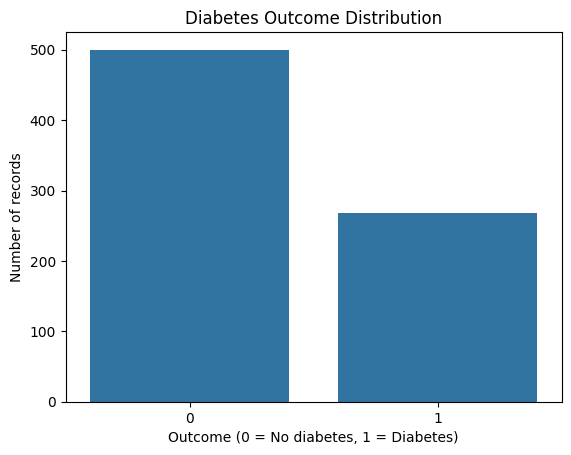

In [34]:
sns.countplot(data=df, x="Outcome")
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No diabetes, 1 = Diabetes)")
plt.ylabel("Number of records")
plt.show()


In [35]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (614, 8)
Testing data: (154, 8)


In [36]:
for col in columns:
    df[col] = df[col].fillna(df[col].median())

df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df.drop_duplicates(inplace=True)

df.duplicated().sum()

np.int64(0)

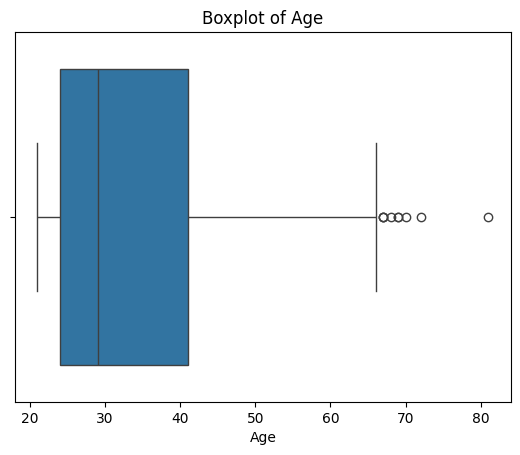

In [39]:
sns.boxplot(x=df["Age"])
plt.title("Boxplot of Age")
plt.show()

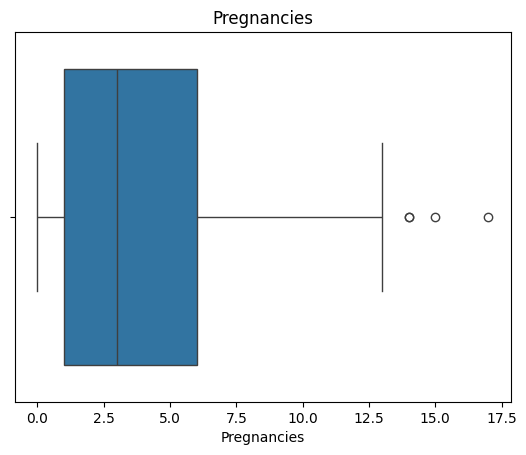

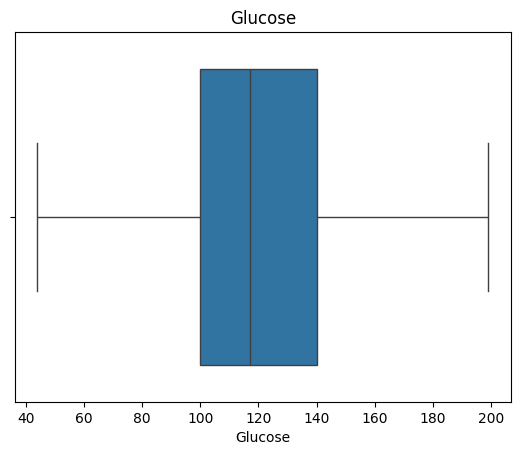

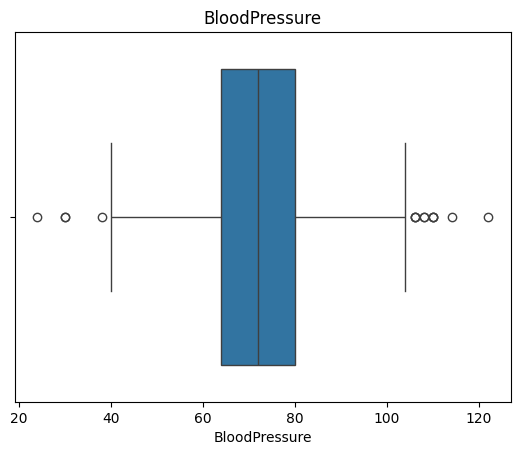

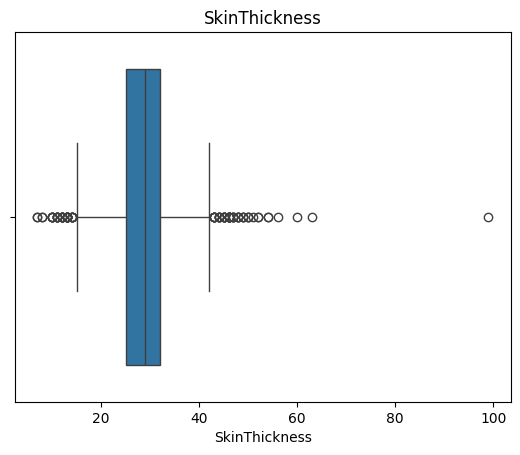

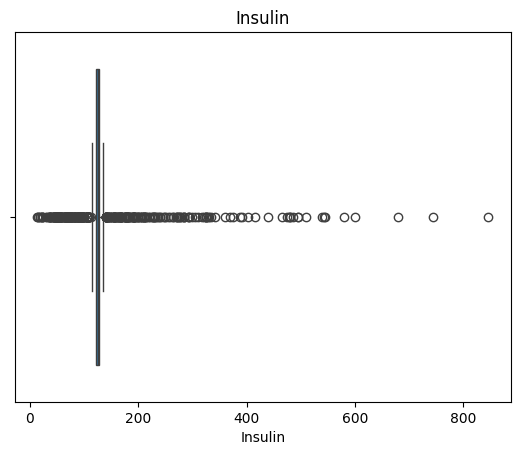

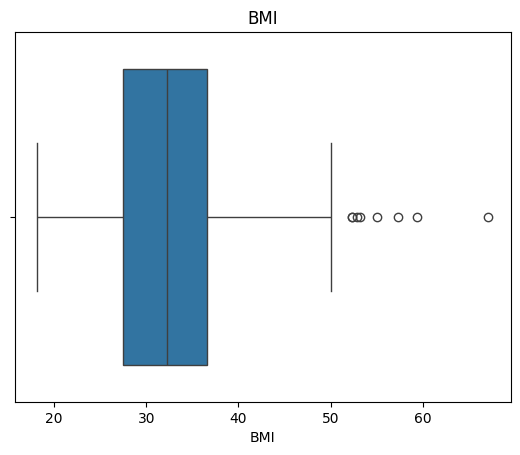

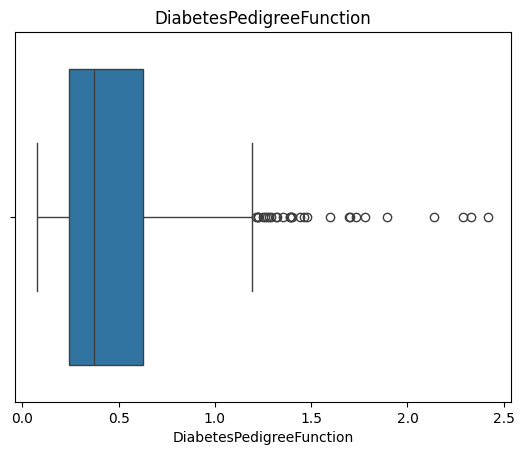

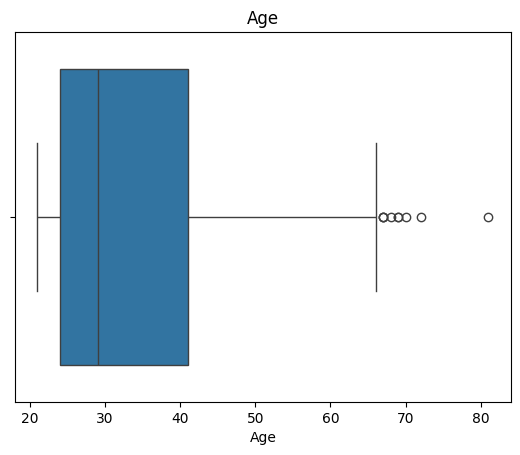

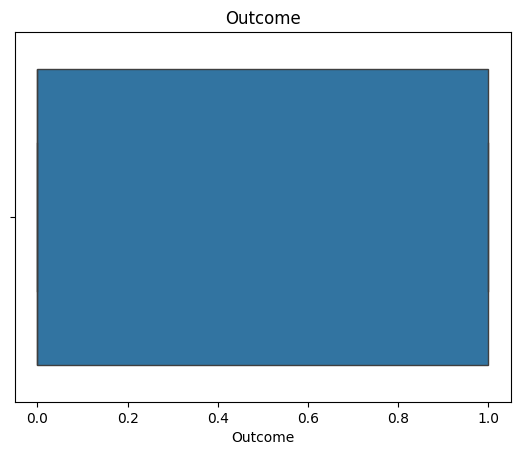

In [40]:
for col in df.select_dtypes(include="number").columns:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

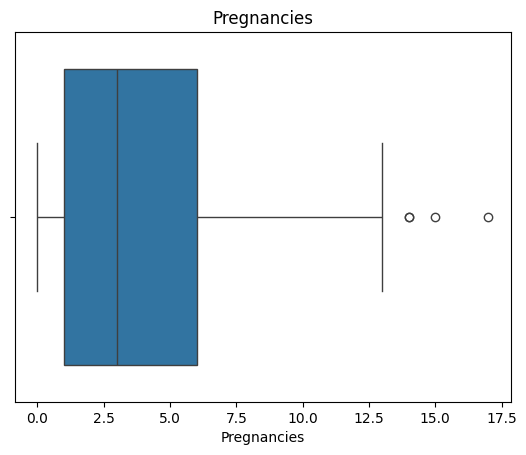

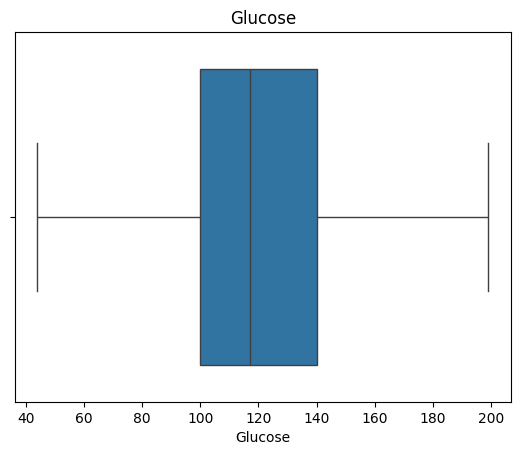

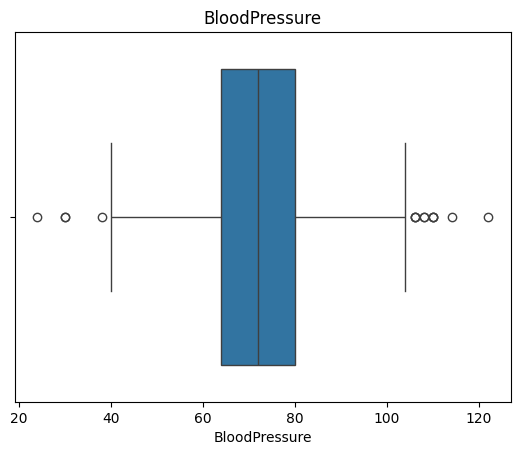

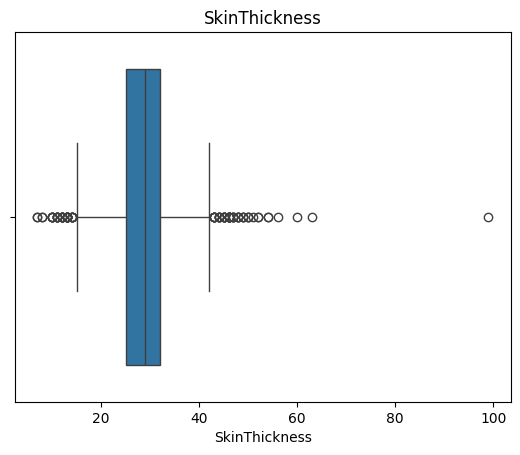

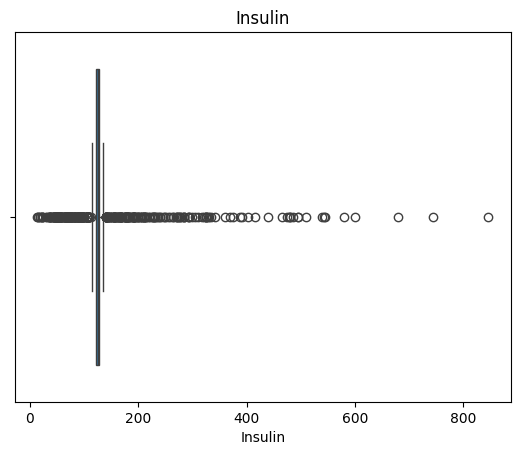

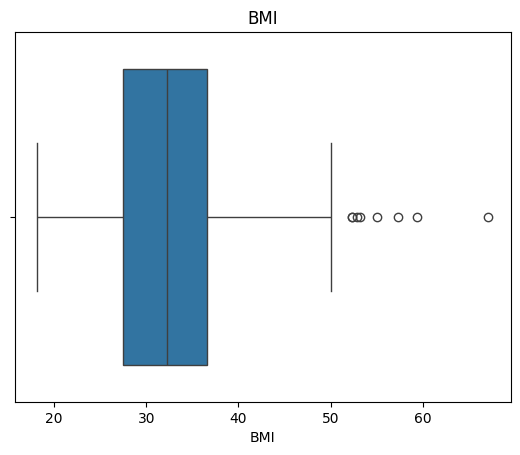

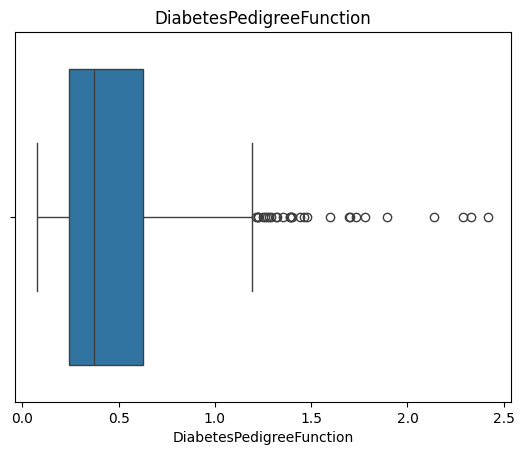

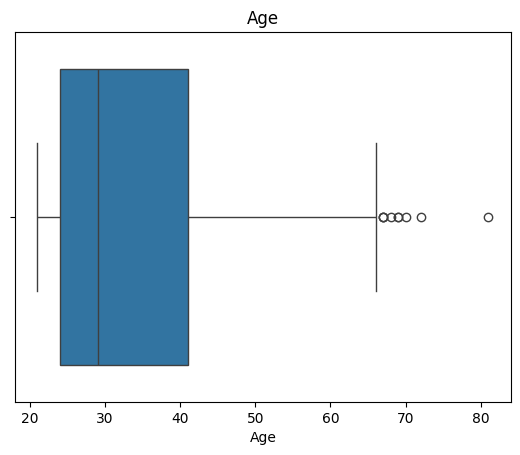

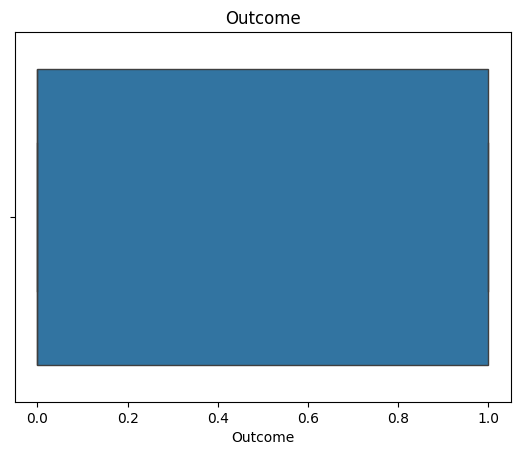

In [41]:
for col in df.select_dtypes(include="number").columns:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

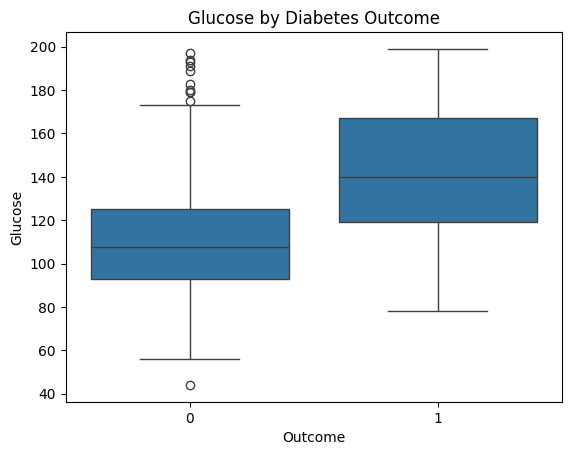

In [42]:
sns.boxplot(x=df["Outcome"], y=df["Glucose"])
plt.title("Glucose by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Glucose")
plt.show()

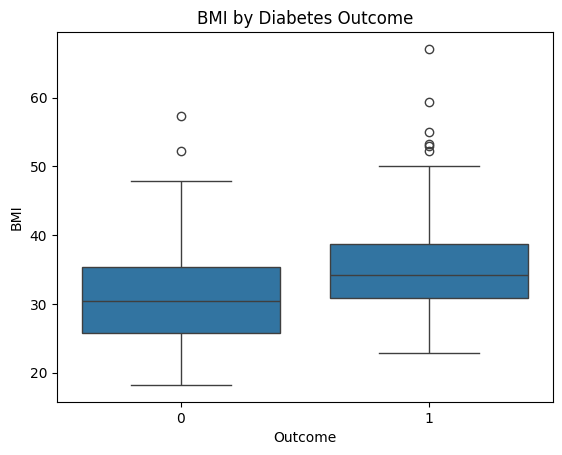

In [43]:
sns.boxplot(x=df["Outcome"], y=df["BMI"])
plt.title("BMI by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("BMI")
plt.show()

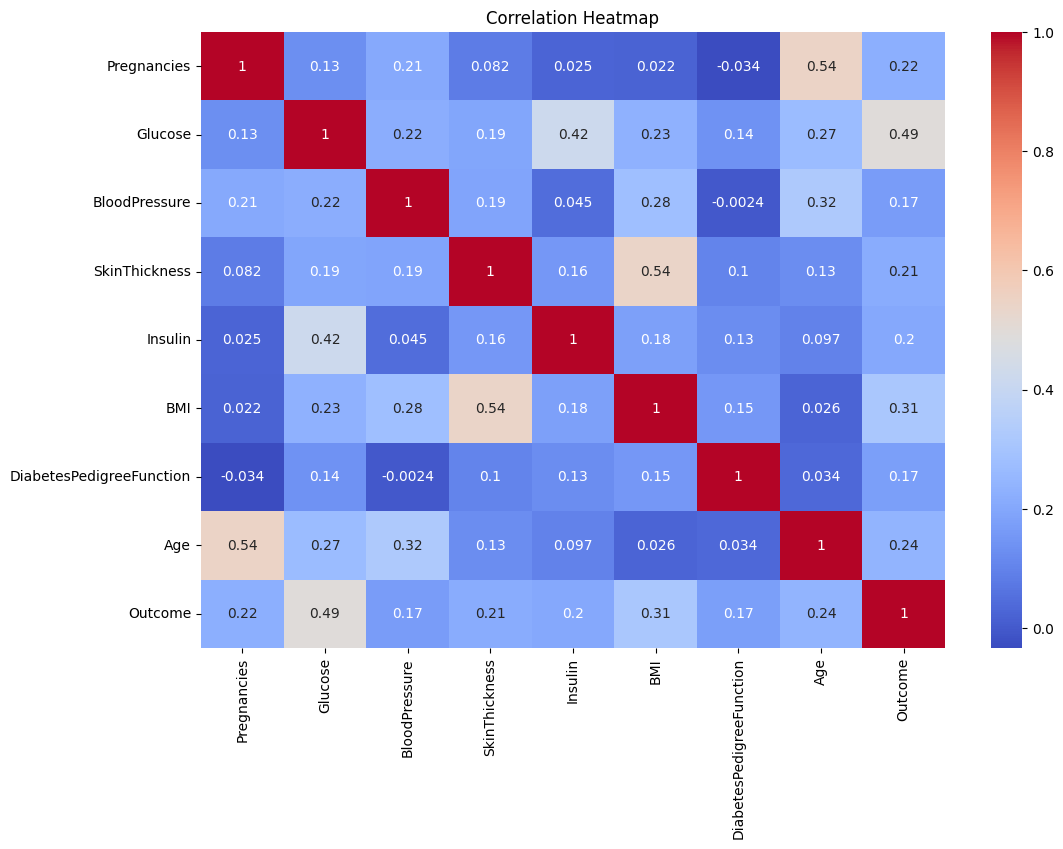

In [44]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [45]:
df.select_dtypes(include="object").columns

Index([], dtype='object')

In [46]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

print(X.shape)
print(y.shape)

(768, 8)
(768,)


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(614, 8)
(154, 8)
(614,)
(154,)


In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [49]:
y_pred = model.predict(X_test)

print(y_pred)

[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 0 0 0 0 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 0 0 0 0 0 1 0 1 0 1 0 1
 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 1 0 0 0 1 0]


In [50]:
result = pd.DataFrame({"Actual": y_test,"Predicted": y_pred})

result.head(10)

,Actual,Predicted
44,0,1
672,0,0
700,0,0
630,1,0
81,0,0
389,0,0
387,1,0
408,1,1
163,0,0
335,0,1


In [51]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.7012987012987013

In [52]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



In [53]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[81 19]
 [27 27]]


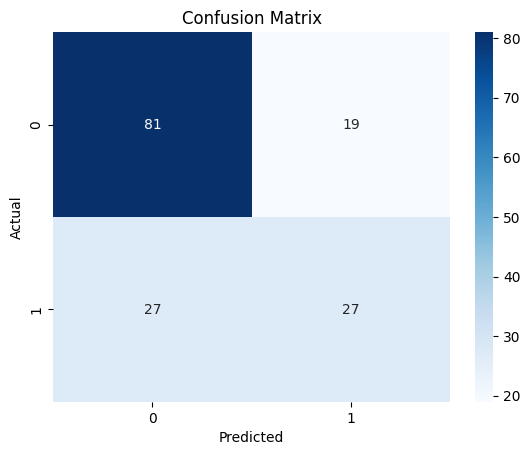

In [54]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [55]:
print("Training accuracy:", model.score(X_train, y_train))
print("Testing accuracy:", model.score(X_test, y_test))

Training accuracy: 0.7931596091205212
Testing accuracy: 0.7012987012987013


In [56]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))

ROC-AUC Score: 0.812962962962963


# IN CONCLUSION
In this project, I worked with the Pima Indians Diabetes dataset to create a Logistic Regression model. First, I cleaned the data by handling missing values and duplicates. Then, I used different graphs to understand the data better.

After that, I trained and tested the model and checked how well it performed using different evaluation methods.

Through this project, I learned how to clean data, create graphs and build a basic machine learning model using Python.